# AstroShield — constelación inteligente sobre Veguitto

**Fundamentos de Inteligencia Artificial** · Ing. Carlos André Castro Rodríguez · UT Cancún

**Equipo:** Ríos Astudillo Daniel Eduardo · Itza Santizo Jarett Osiel · Salinas Beatriz Erick · Navarrete Tzuc Jorge

Este notebook es el archivo principal del proyecto. Corre el algoritmo evolutivo, muestra la constelación en un globo 3D y ejecuta todas las pruebas. **Todos los números que aparecen aquí salen de ejecutar el código**; las semillas aleatorias están fijas para que cualquiera pueda repetir exactamente las mismas corridas.

| Documento | Contenido |
|---|---|
| `docs/01-definicion-del-problema.md` | Representación, cobertura, aptitud, restricciones, parámetros (Entregable 1) |
| `docs/03-pruebas-y-validacion.md` | Las 10 pruebas con condiciones, resultados e interpretación (Entregable 3) |
| `docs/04-analisis-de-resultados.md` | Respuestas a las preguntas del análisis (Entregable 4) |
| `resultados/` | Globos 3D en HTML, mapas, gráficas y `resumen.json` con todos los números |

**Abrir en Google Colab:** https://colab.research.google.com/github/jorgemx546/astroshield/blob/main/AstroShield.ipynb · luego *Entorno de ejecución → Ejecutar todas*. La primera celda clona el repositorio por su cuenta; no hay que subir nada.

In [1]:
import os, sys, json, subprocess
from pathlib import Path

# En Google Colab: traer el repositorio y trabajar dentro de él.
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("/content/astroshield").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/jorgemx546/astroshield.git", "/content/astroshield"], check=True)
    os.chdir("/content/astroshield")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import Markdown, display

from astroshield.escenario import escenario_etapa1, escenario_etapa2
from astroshield.evaluacion import Evaluador
from astroshield.evolutivo import Configuracion, ejecutar
from astroshield import experimentos as ex
from astroshield import visualizacion as vz

pio.renderers.default = "colab" if EN_COLAB else "notebook_connected"
plt.rcParams["figure.dpi"] = 100

def tabla(filas, columnas=None, titulos=None):
    """Muestra una lista de diccionarios como tabla Markdown."""
    columnas = columnas or list(filas[0].keys())
    titulos = titulos or columnas
    fmt = lambda v: (f"{v:.4f}".rstrip("0").rstrip(".") if isinstance(v, float)
                     else "sí" if v is True else "no" if v is False else "—" if v is None else str(v))
    lineas = ["| " + " | ".join(titulos) + " |", "|" + "---|" * len(columnas)]
    lineas += ["| " + " | ".join(fmt(f.get(c)) for c in columnas) + " |" for f in filas]
    display(Markdown("\n".join(lineas)))

## 1. El escenario: planeta Veguitto

Veguitto es un planeta ficticio de **5,200 km de radio** (lo definimos nosotros por indicación del docente). Las coordenadas, prioridades, zonas y el radio de observación de 300 km son los del enunciado; solo cambian el planeta y los nombres.

In [2]:
e2 = escenario_etapa2()
ev2 = Evaluador(e2)
tabla([{"Región": r.nombre, "Equivale a": r.equivale_a, "Centro": f"{r.lat}°, {r.lon}°",
        "Prioridad": r.prioridad, "Peso": int(e2.pesos[r.prioridad])} for r in e2.regiones])
tabla([{"Zona": z.nombre, "Tipo": z.tipo, "Centro": f"{z.lat}°, {z.lon}°", "Radio": f"{z.radio_grados}°"} for z in e2.zonas])
print(f"Huella de un satélite: {ev2.huella:.3f}° ({np.radians(ev2.huella) * e2.planeta.radio_km:.0f} km)")
print(f"Radio de una región:   {ev2.radio_region:.3f}° (300 km)")
print(f"Un satélite cubre una región completa si está a menos de {ev2.huella - ev2.radio_region:.2f}° de su centro")
print(f"Separación mínima entre regiones: {ev2.separacion_minima_entre_regiones():.1f}° (> {2*(ev2.huella+ev2.radio_region):.1f}°: un satélite no ve dos regiones)")
print(f"Cota superior de la aptitud: {ev2.cota_superior():.4f}")

| Región | Equivale a | Centro | Prioridad | Peso |
|---|---|---|---|---|
| Meseta Saiyan | Península de Yucatán, México | 20.5°, -89.0° | alta | 3 |
| Selva Namek | Amazonía brasileña | -3.5°, -62.0° | alta | 3 |
| Valle Capsule | California, EE. UU. | 36.8°, -119.4° | media | 2 |
| Llanura Kaio | Región del Sahel, África | 15.0°, 0.0° | media | 2 |
| Archipiélago Zenkai | Japón | 36.0°, 138.0° | media | 2 |
| Desierto Kami | Interior de Australia | -25.0°, 133.0° | normal | 1 |

| Zona | Tipo | Centro | Radio |
|---|---|---|---|
| Cinturón de escombros Norte | escombros | 45.0°, -35.0° | 12.0° |
| Cinturón de escombros Sur | escombros | -30.0°, -120.0° | 10.0° |
| Casquete de escombros polar | escombros | 78.0°, 30.0° | 8.0° |
| Objeto A | ocupada | 10.0°, 45.0° | 5.0° |
| Objeto B | ocupada | -15.0°, 110.0° | 5.0° |

Huella de un satélite: 4.774° (433 km)
Radio de una región:   3.306° (300 km)
Un satélite cubre una región completa si está a menos de 1.47° de su centro
Separación mínima entre regiones: 31.1° (> 16.2°: un satélite no ve dos regiones)
Cota superior de la aptitud: 1.0462


## 2. Prueba 1 — Escenario inicial

Se corre el algoritmo en las dos etapas con la **semilla 42**: 80 configuraciones × 150 generaciones = 12,000 evaluaciones por corrida.

In [3]:
p1 = ex.prueba_escenario_inicial()
for clave in ("etapa1", "etapa2"):
    d = p1[clave]
    print(f"{d['escenario']}: aptitud {d['resumen']['aptitud']} ({d['resumen']['porcentaje_cota']} % de la cota), "
          f"{d['resumen']['regiones_cubiertas']}/6 cubiertas, válida={d['resumen']['valida']}, "
          f"suficientemente buena={d['resumen']['suficientemente_buena']}, "
          f"{d['evaluaciones']} evaluaciones en {d['segundos']} s")
    print(f"   mejor de la población inicial: aptitud {d['resumen_inicial']['aptitud']}, "
          f"{d['resumen_inicial']['regiones_cubiertas']}/6 cubiertas")

Etapa 1 — sin restricciones: aptitud 1.0291 (98.4 % de la cota), 6/6 cubiertas, válida=True, suficientemente buena=True, 12000 evaluaciones en 0.58 s
   mejor de la población inicial: aptitud 0.3867, 0/6 cubiertas
Etapa 2 — con restricciones: aptitud 1.0462 (100.0 % de la cota), 6/6 cubiertas, válida=True, suficientemente buena=True, 12000 evaluaciones en 0.66 s
   mejor de la población inicial: aptitud 0.3867, 0/6 cubiertas


In [4]:
rep2 = p1["etapa2"]["reporte"]
r2 = p1["etapa2"]["resultado"]
tabla([{"Región": x["region"], "Prioridad": x["prioridad"], "Cobertura": f"{x['cobertura']:.0%}",
        "Redundancia": f"{x['redundancia']:.0%}", "¿Cubierta?": "sí" if x["cubierta"] else "no",
        "Satélites que la ven": ", ".join(map(str, x["satelites"])) or "—"} for x in rep2["regiones"]])
tabla([{"Satélite": i, "Latitud": f"{p[0]:.2f}°", "Longitud": f"{p[1]:.2f}°"} for i, p in enumerate(r2.mejor)])

| Región | Prioridad | Cobertura | Redundancia | ¿Cubierta? | Satélites que la ven |
|---|---|---|---|---|---|
| Meseta Saiyan | alta | 100% | 100% | sí | 3, 6 |
| Selva Namek | alta | 100% | 100% | sí | 0, 5 |
| Valle Capsule | media | 100% | 0% | sí | 4 |
| Llanura Kaio | media | 100% | 0% | sí | 7 |
| Archipiélago Zenkai | media | 100% | 0% | sí | 2 |
| Desierto Kami | normal | 100% | 0% | sí | 1 |

| Satélite | Latitud | Longitud |
|---|---|---|
| 0 | -3.44° | -63.41° |
| 1 | -24.65° | 132.18° |
| 2 | 35.63° | 136.35° |
| 3 | 21.61° | -88.46° |
| 4 | 37.95° | -119.17° |
| 5 | -4.23° | -61.39° |
| 6 | 19.53° | -89.34° |
| 7 | 16.15° | -0.90° |

### Visualización 3D (etapa 2)

Se puede **girar** con el ratón y alternar entre la mejor configuración de la población inicial y la final con los botones de abajo a la izquierda. Colores de las regiones: verde = cubierta, naranja = parcial, rojo = sin cobertura. Las zonas prohibidas se dibujan a la altura de la órbita (línea gruesa) y proyectadas sobre la superficie (punteada). Los rombos son los satélites; el círculo debajo de cada uno es su huella.

*Si la figura no aparece (por ejemplo, en la vista previa de GitHub), abrir `resultados/globo_etapa2.html` en el navegador.*

In [5]:
fig = vz.globo_3d(ev2, r2.mejor, inicial=r2.mejor_inicial)
fig.show()

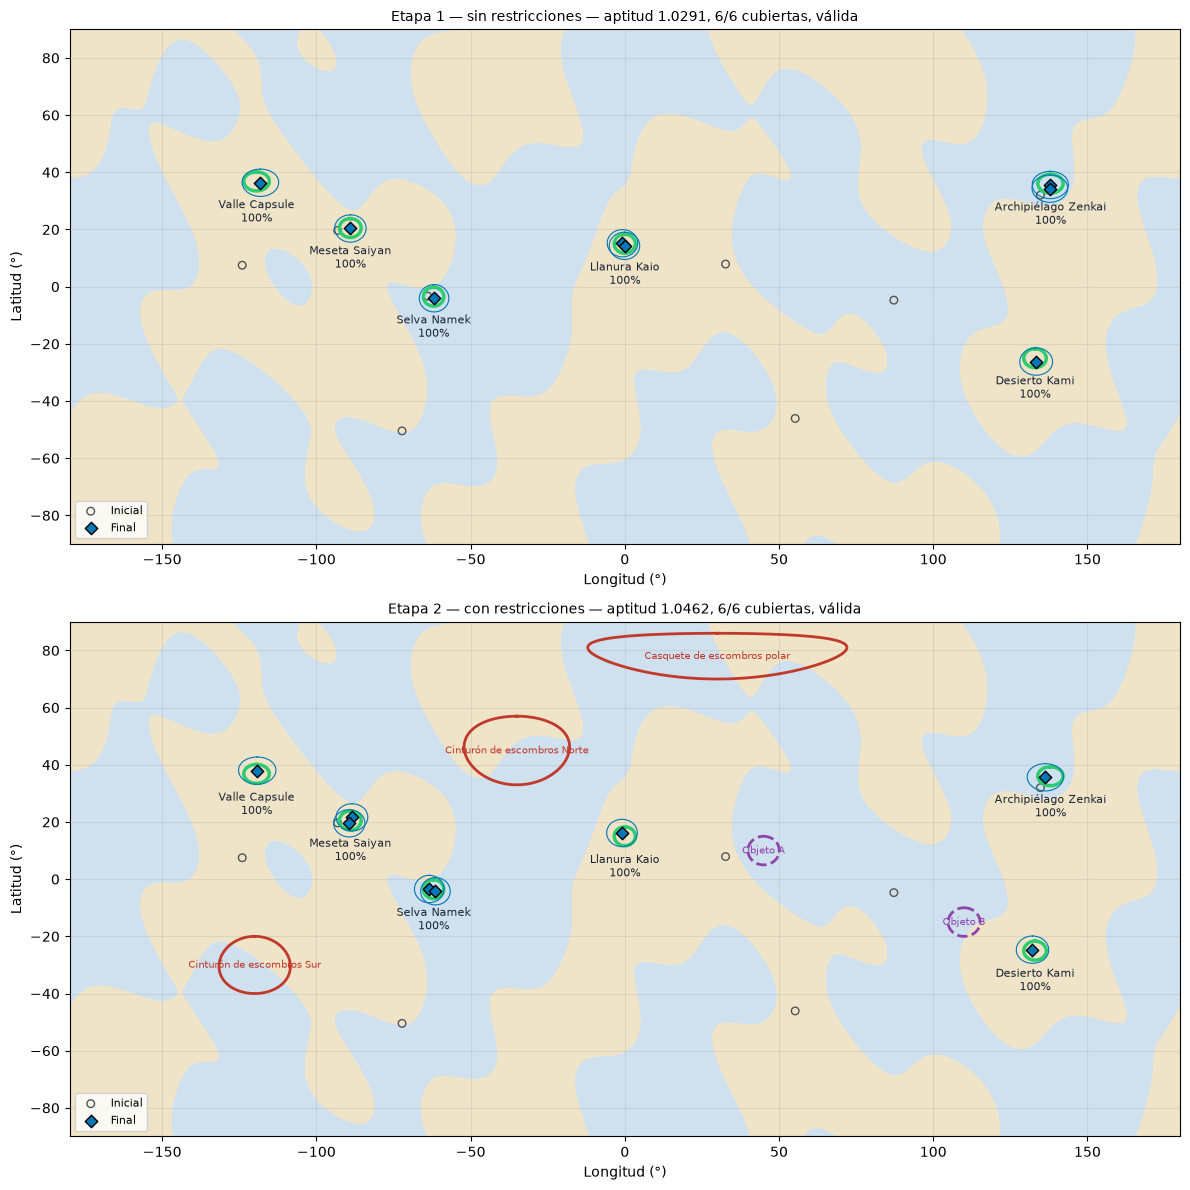

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 12))
vz.mapa(p1["etapa1"]["evaluador"], p1["etapa1"]["resultado"].mejor, ax=ejes[0], inicial=p1["etapa1"]["resultado"].mejor_inicial)
vz.mapa(ev2, r2.mejor, ax=ejes[1], inicial=r2.mejor_inicial)
plt.tight_layout(); plt.show()

**Interpretación.** En las dos etapas el algoritmo pasa de una población inicial que no cubre ninguna región a una constelación válida que cubre las 6. En la etapa 2 (semilla 42) llega exactamente a la cota superior: un satélite por región y los dos sobrantes duplicando las dos regiones de prioridad alta. En la etapa 1, con la misma semilla, se queda en el 98.4 % de la cota porque duplicó dos regiones medias en lugar de las altas. Eso **no** se debe a que la etapa 1 sea más difícil (tiene menos restricciones), sino al azar de la búsqueda: lo confirma la prueba 7.

## 3. Prueba 2 — Evolución de la calidad

| Generación | Mejor F | F promedio (válidas) | % válidas | Regiones cubiertas | σ mutación |
|---|---|---|---|---|---|
| 0 | 0.3867 | 0.0197 | 81.2 | 0 | 8 |
| 5 | 0.659 | 0.268 | 91.2 | 1 | 7.17 |
| 10 | 0.7751 | 0.4825 | 83.8 | 1 | 6.42 |
| 25 | 0.9179 | 0.5956 | 75 | 4 | 4.61 |
| 50 | 0.9578 | 0.6885 | 72.5 | 4 | 2.66 |
| 75 | 1.0297 | 0.7465 | 66.2 | 6 | 1.53 |
| 100 | 1.0437 | 0.8052 | 63.7 | 6 | 0.88 |
| 149 | 1.0462 | 0.7638 | 58.8 | 6 | 0.3 |

Generación en que alcanza el 95 % de la cota: 64 · el 98 %: 73 · la cota: 130


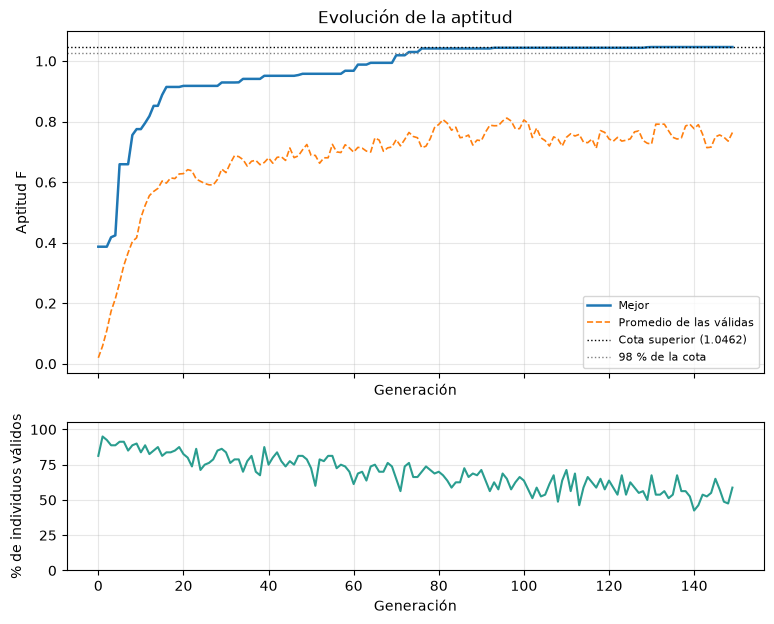

In [7]:
p2 = ex.prueba_evolucion(r2, ev2.cota_superior())
tabla(p2["tabla"], ["generacion", "mejor_aptitud", "promedio_validas", "porcentaje_validas", "regiones_cubiertas", "sigma"],
      ["Generación", "Mejor F", "F promedio (válidas)", "% válidas", "Regiones cubiertas", "σ mutación"])
print(f"Generación en que alcanza el 95 % de la cota: {p2['gen_95']} · el 98 %: {p2['gen_98']} · la cota: {p2['gen_cota']}")
fig, ejes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
vz.grafica_evolucion(r2.historial, cota=ev2.cota_superior(), ax=ejes[0])
vz.grafica_validez(r2.historial, ax=ejes[1]); plt.show()

**Interpretación.** La mejor aptitud sube rápido en las primeras 25 generaciones (de 0.39 a 0.92: se encuentran las primeras regiones) y luego por escalones: cada escalón es una región nueva que entra en una huella. Después de la generación 75 ya están las 6 regiones y lo que mejora es el ajuste fino (redundancia), cuando σ ya es pequeño. El promedio de las válidas queda lejos del mejor porque la mutación y la reubicación siguen metiendo variedad, y por eso el porcentaje de válidas baja con las generaciones: la población explora cerca de los bordes de las zonas. Que la curva se aplane no prueba por sí sola que sea el óptimo; aquí lo sabemos porque toca la cota superior.

## 4. Pruebas 3 y 4 — Zonas restringidas y posiciones ocupadas

In [8]:
p34 = ex.prueba_restricciones(ev2, r2)
display(Markdown("**Margen de la solución final respecto a cada zona** (margen > 0 = afuera):"))
tabla(p34["margenes"], ["zona", "tipo", "radio", "satelite_mas_cercano", "distancia", "margen"],
      ["Zona", "Tipo", "Radio (°)", "Satélite más cercano", "Distancia (°)", "Margen (°)"])
print(f"De 1,000 configuraciones al azar: {p34['azar_invalidas_pct']} % son inválidas; "
      f"{p34['azar_satelites_en_zona_pct']} % de sus satélites caen en una zona prohibida.")
print("Satélites al azar dentro de cada zona:", p34["azar_por_zona"])
display(Markdown("**Inyección:** se mete el satélite 7 de la solución final en el centro de cada zona."))
tabla(p34["inyecciones"], ["zona", "tipo", "detectada", "violacion", "aptitud_sin_restricciones"],
      ["Zona", "Tipo", "¿Detectada como inválida?", "Violación (°)", "Aptitud que tendría"])
print("Soluciones de la etapa 1 (sin restricciones) que resultan válidas en la etapa 2:", p34["etapa1_validas_en_etapa2"])

**Margen de la solución final respecto a cada zona** (margen > 0 = afuera):

| Zona | Tipo | Radio (°) | Satélite más cercano | Distancia (°) | Margen (°) |
|---|---|---|---|---|---|
| Cinturón de escombros Norte | escombros | 12 | 7 | 40.61 | 28.61 |
| Cinturón de escombros Sur | escombros | 10 | 6 | 57.66 | 47.66 |
| Casquete de escombros polar | escombros | 8 | 2 | 58.52 | 50.52 |
| Objeto A | ocupada | 5 | 7 | 45.05 | 40.05 |
| Objeto B | ocupada | 5 | 1 | 22.94 | 17.94 |

De 1,000 configuraciones al azar: 21.5 % son inválidas; 2.8 % de sus satélites caen en una zona prohibida.
Satélites al azar dentro de cada zona: {'Cinturón de escombros Norte': 94, 'Cinturón de escombros Sur': 63, 'Casquete de escombros polar': 41, 'Objeto A': 18, 'Objeto B': 8}


**Inyección:** se mete el satélite 7 de la solución final en el centro de cada zona.

| Zona | Tipo | ¿Detectada como inválida? | Violación (°) | Aptitud que tendría |
|---|---|---|---|---|
| Cinturón de escombros Norte | escombros | sí | 12 | 0.8923 |
| Cinturón de escombros Sur | escombros | sí | 10 | 0.8923 |
| Casquete de escombros polar | escombros | sí | 8 | 0.8923 |
| Objeto A | ocupada | sí | 5 | 0.8923 |
| Objeto B | ocupada | sí | 5 | 0.8923 |

Soluciones de la etapa 1 (sin restricciones) que resultan válidas en la etapa 2: 10/10


**Interpretación.** La solución final queda lejos de todas las zonas; la más cercana es Objeto B. Las cinco inyecciones se detectan y la violación medida es justo el radio de la zona, porque el satélite quedó en su centro. Las restricciones sí actúan durante la búsqueda: uno de cada cinco individuos al azar es inválido y nunca puede ganarle a uno válido. Una observación honesta: en este escenario las zonas están lejos de las regiones, así que **no cambian el óptimo**. Las 10 soluciones de la etapa 1 también resultan válidas en la etapa 2. Para ver un efecto real sobre la solución hay que acercar las restricciones a las regiones (pruebas 5 y 6).

## 5. Prueba 5 — Espacio reducido

In [9]:
p5 = ex.prueba_espacio_reducido()
tabla(p5["saiyan"], ["caso", "aptitud", "porcentaje_cota", "valida", "regiones_cubiertas", "satelites_en_saiyan", "distancia_mas_cercano_saiyan"],
      ["Caso", "F", "% cota", "Válida", "Cubiertas", "Satélites sobre M. Saiyan", "Distancia del más cercano (°)"])
c5 = p5["saiyan_5_semillas"]
print(f"Con la zona sobre Meseta Saiyan, 5 semillas: F = {c5['aptitudes']}, cubiertas = {c5['regiones_cubiertas']}, "
      f"suficientemente buenas = {c5['suficientemente_buenas']}/5")
print("Cobertura de Meseta Saiyan por semilla:", [c["Meseta Saiyan"] for c in c5["coberturas"]])
print("Cobertura de Desierto Kami por semilla:", [c["Desierto Kami"] for c in c5["coberturas"]])
tabla(p5["progresivo"], ["zonas_extra", "area_prohibida_pct", "azar_validas_pct", "aptitud", "porcentaje_cota", "valida", "regiones_cubiertas"],
      ["Zonas extra de 6°", "% del espacio prohibido", "% válidas al azar", "F final", "% cota", "Válida", "Cubiertas"])

| Caso | F | % cota | Válida | Cubiertas | Satélites sobre M. Saiyan | Distancia del más cercano (°) |
|---|---|---|---|---|---|---|
| Etapa 2 (referencia) | 1.0462 | 100 | sí | 6 | 2 | 1.02 |
| + zona de 2.5° sobre Meseta Saiyan | 1.0004 | 95.6 | sí | 5 | 2 | 2.83 |

Con la zona sobre Meseta Saiyan, 5 semillas: F = [1.0004, 1.0227, 1.0075, 0.9859, 1.0249], cubiertas = [5, 6, 5, 3, 6], suficientemente buenas = 0/5
Cobertura de Meseta Saiyan por semilla: [0.973, 0.973, 0.946, 0.946, 1.0]
Cobertura de Desierto Kami por semilla: [0.919, 1.0, 1.0, 0.838, 1.0]


| Zonas extra de 6° | % del espacio prohibido | % válidas al azar | F final | % cota | Válida | Cubiertas |
|---|---|---|---|---|---|---|
| 0 | 2.7 | 82.4 | 1.0462 | 100 | sí | 6 |
| 10 | 5.5 | 65.6 | 1.0424 | 99.6 | sí | 6 |
| 20 | 8.2 | 52.5 | 1.0405 | 99.5 | sí | 6 |
| 40 | 13.4 | 33.3 | 1.0324 | 98.7 | sí | 5 |

**Interpretación.** Con una nube de escombros de 2.5° justo encima de Meseta Saiyan ya no se puede poner un satélite en su centro. El algoritmo lo resuelve con **dos satélites alrededor de la zona** (a 2.8° del centro), que juntos ven casi toda la región. Ese satélite extra sale de la redundancia, y el resultado baja del óptimo: ninguna de las 5 semillas cumple el criterio de "suficientemente buena". Al agregar zonas al azar, el espacio prohibido pasa de 2.7 % a 13.4 % y la fracción de configuraciones válidas al azar cae de 82 % a 33 %; aun así el algoritmo siempre termina con una solución válida, aunque con 40 zonas deja Desierto Kami parcial. **Ojo:** la cota superior (1.0462) supone que cada región se cubre con un solo satélite; con zonas encima de una región esa cota ya no se puede alcanzar, así que el porcentaje de la cota subestima qué tan buena es la solución.

## 6. Prueba 6 — Condiciones difíciles e inviables

**a) Objeto B movido sobre Desierto Kami (radio 5°)**

  Alcanzabilidad (máxima cobertura posible por región): {'Meseta Saiyan': 1.0, 'Selva Namek': 1.0, 'Valle Capsule': 1.0, 'Llanura Kaio': 1.0, 'Archipiélago Zenkai': 1.0, 'Desierto Kami': 0.973}
  Resultado: F = 0.9877, válida = True, violación = 0.0°, cubiertas = 5/6, problemas reportados = 0
  Cobertura obtenida: {'Meseta Saiyan': 1.0, 'Selva Namek': 1.0, 'Valle Capsule': 1.0, 'Llanura Kaio': 1.0, 'Archipiélago Zenkai': 1.0, 'Desierto Kami': 0.622}
  5 semillas: F = [0.9877, 0.9948, 0.9784, 0.9896, 0.9834], cubiertas = [5, 5, 5, 5, 5]


**b) Zona de 9° sobre Meseta Saiyan**

  Alcanzabilidad (máxima cobertura posible por región): {'Meseta Saiyan': 0.0, 'Selva Namek': 1.0, 'Valle Capsule': 1.0, 'Llanura Kaio': 1.0, 'Archipiélago Zenkai': 1.0, 'Desierto Kami': 1.0}
  Resultado: F = 0.8185, válida = True, violación = 0.0°, cubiertas = 5/6, problemas reportados = 0
  Cobertura obtenida: {'Meseta Saiyan': 0.0, 'Selva Namek': 1.0, 'Valle Capsule': 1.0, 'Llanura Kaio': 1.0, 'Archipiélago Zenkai': 1.0, 'Desierto Kami': 1.0}
  5 semillas: F = [0.8185, 0.8185, 0.8156, 0.8231, 0.8189], cubiertas = [5, 5, 5, 5, 4]


**c) Todo el planeta prohibido**

  Alcanzabilidad (máxima cobertura posible por región): {'Meseta Saiyan': 0.0, 'Selva Namek': 0.0, 'Valle Capsule': 0.0, 'Llanura Kaio': 0.0, 'Archipiélago Zenkai': 0.0, 'Desierto Kami': 0.0}
  Resultado: F = 0.0, válida = False, violación = 8.373°, cubiertas = 0/6, problemas reportados = 17
  Cobertura obtenida: {'Meseta Saiyan': 0.0, 'Selva Namek': 0.0, 'Valle Capsule': 0.0, 'Llanura Kaio': 0.0, 'Archipiélago Zenkai': 0.0, 'Desierto Kami': 0.0}


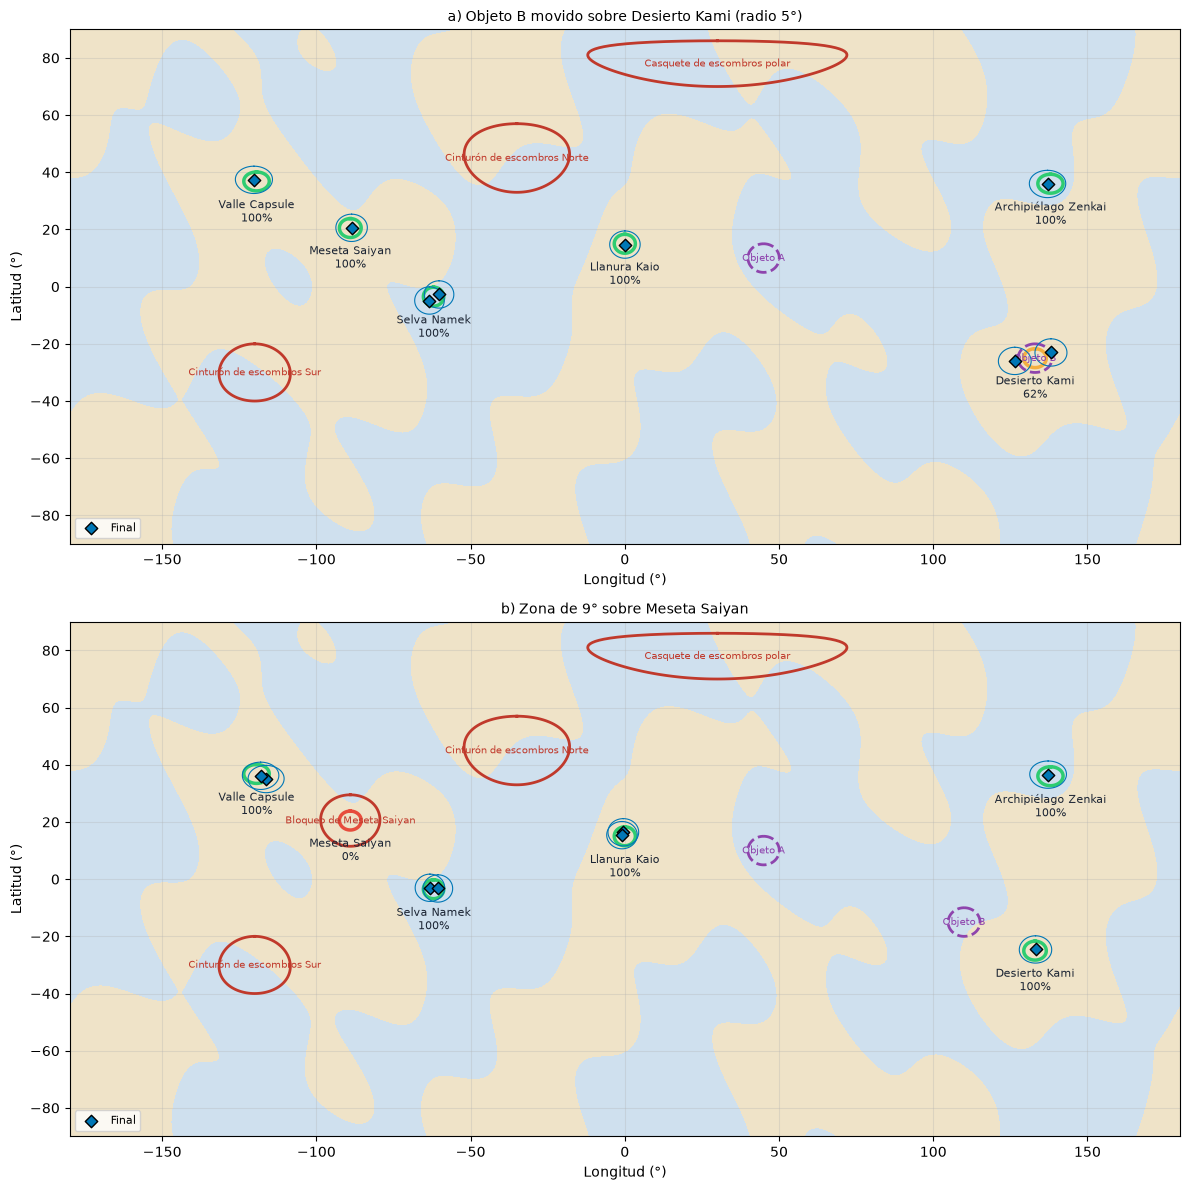

In [10]:
p6 = ex.prueba_condiciones_dificiles()
for caso in p6:
    s = caso["resumen"]
    display(Markdown(f"**{caso['caso']}**"))
    print("  Alcanzabilidad (máxima cobertura posible por región):", caso["alcanzabilidad"])
    print(f"  Resultado: F = {s['aptitud']}, válida = {s['valida']}, violación = {s['violacion']}°, "
          f"cubiertas = {s['regiones_cubiertas']}/6, problemas reportados = {caso['problemas']}")
    print("  Cobertura obtenida:", s["cobertura"])
    if caso["cinco_semillas"]:
        c = caso["cinco_semillas"]
        print(f"  5 semillas: F = {c['aptitudes']}, cubiertas = {c['regiones_cubiertas']}")
fig, ejes = plt.subplots(2, 1, figsize=(12, 12))
for ax, caso in zip(ejes, p6[:2]):
    vz.mapa(caso["evaluador"], caso["resultado"].mejor, ax=ax, titulo=caso["caso"])
plt.tight_layout(); plt.show()

In [11]:
vz.globo_3d(p6[1]["evaluador"], p6[1]["resultado"].mejor, titulo=p6[1]["caso"]).show()

**Interpretación.**

- **a) Difícil.** Con Objeto B encima de Desierto Kami, el centro de la región ya no se puede ver desde ninguna posición permitida: el análisis de alcanzabilidad dice que como máximo se ve el 97.3 % de la región. El algoritmo nunca llega a ese máximo. Según la semilla, Kami queda entre 0 % y 62 %. Como Kami es de prioridad normal (peso 1), al algoritmo le conviene más usar esos satélites para redundancia de las regiones altas que pelear por una región difícil y barata. Es una **limitación del criterio de evaluación**, no un error del código: la función de aptitud permite abandonar una región de baja prioridad.
- **b) Inviable para una región.** Con una zona de 9° sobre Meseta Saiyan, ningún satélite permitido llega a verla (alcanzabilidad 0). El sistema no se rompe ni la reporta como cubierta. Entrega una configuración válida con las otras 5 regiones cubiertas y deja Meseta Saiyan en 0 %. Así se ve que el sistema distingue entre "no la encontró" y "no se puede".
- **c) Inviable total.** Si todo el planeta está prohibido no existe ninguna configuración válida. El algoritmo no inventa una: devuelve la que **menos viola** (las reglas de Deb comparan por violación cuando no hay válidas), la marca como **inválida** con su violación (8.37°) y lista los 17 problemas. El 0 % de válidas al final lo confirma.

## 7. Prueba 7 — Variación entre ejecuciones

In [12]:
p7 = ex.prueba_variacion()
filas = [{"Método": k, **v} for k, v in p7["estadisticas"].items()]
tabla(filas, ["Método", "media", "desviacion", "minimo", "maximo", "seis_cubiertas", "suficientemente_buenas", "corridas"],
      ["Método", "F media", "Desv. est.", "F mín.", "F máx.", "6 cubiertas", "Suficientemente buenas", "Corridas"])
print(f"Todas con el mismo presupuesto: {p7['evaluaciones_por_corrida']} evaluaciones por corrida.")
tabla([{k: f[k] for k in ["semilla", "aptitud", "regiones_cubiertas", "gen_98", "segundos"]} | {"Duplicadas": ", ".join(f["regiones_duplicadas"]) or "—"}
       for f in p7["filas"]], ["semilla", "aptitud", "regiones_cubiertas", "gen_98", "segundos", "Duplicadas"],
      ["Semilla", "F", "Cubiertas", "Gen. al 98 %", "Segundos", "Regiones con redundancia completa"])

| Método | F media | Desv. est. | F mín. | F máx. | 6 cubiertas | Suficientemente buenas | Corridas |
|---|---|---|---|---|---|---|---|
| Evolutivo (informado) | 1.039 | 0.006 | 1.0191 | 1.0462 | 18 | 18 | 20 |
| Evolutivo ciego | 0.9809 | 0.0418 | 0.8983 | 1.0437 | 4 | 4 | 20 |
| Búsqueda aleatoria | 0.3583 | 0.0488 | 0.2931 | 0.4761 | 0 | 0 | 20 |

Todas con el mismo presupuesto: 12000 evaluaciones por corrida.


| Semilla | F | Cubiertas | Gen. al 98 % | Segundos | Regiones con redundancia completa |
|---|---|---|---|---|---|
| 100 | 1.0437 | 6 | 94 | 0.55 | Selva Namek |
| 101 | 1.0462 | 6 | 95 | 0.58 | Meseta Saiyan, Selva Namek |
| 102 | 1.0405 | 6 | 86 | 0.61 | — |
| 103 | 1.0418 | 6 | 101 | 0.5 | Selva Namek |
| 104 | 1.0347 | 6 | 107 | 0.53 | Valle Capsule |
| 105 | 1.0437 | 6 | 100 | 0.51 | Meseta Saiyan |
| 106 | 1.043 | 6 | 52 | 0.48 | Selva Namek |
| 107 | 1.0366 | 6 | 99 | 0.62 | Valle Capsule |
| 108 | 1.036 | 6 | 105 | 0.5 | Llanura Kaio |
| 109 | 1.0378 | 6 | 70 | 0.48 | Meseta Saiyan, Llanura Kaio |
| 110 | 1.0356 | 6 | 102 | 0.52 | Selva Namek |
| 111 | 1.038 | 6 | 84 | 0.5 | — |
| 112 | 1.0385 | 6 | 77 | 0.56 | Meseta Saiyan, Valle Capsule |
| 113 | 1.0191 | 5 | — | 0.47 | — |
| 114 | 1.0462 | 6 | 62 | 0.54 | Meseta Saiyan, Selva Namek |
| 115 | 1.036 | 6 | 48 | 0.5 | Selva Namek |
| 116 | 1.0395 | 5 | 90 | 0.34 | Meseta Saiyan |
| 117 | 1.0364 | 6 | 90 | 0.63 | Selva Namek |
| 118 | 1.0418 | 6 | 66 | 0.44 | Selva Namek |
| 119 | 1.0449 | 6 | 69 | 0.57 | Selva Namek |

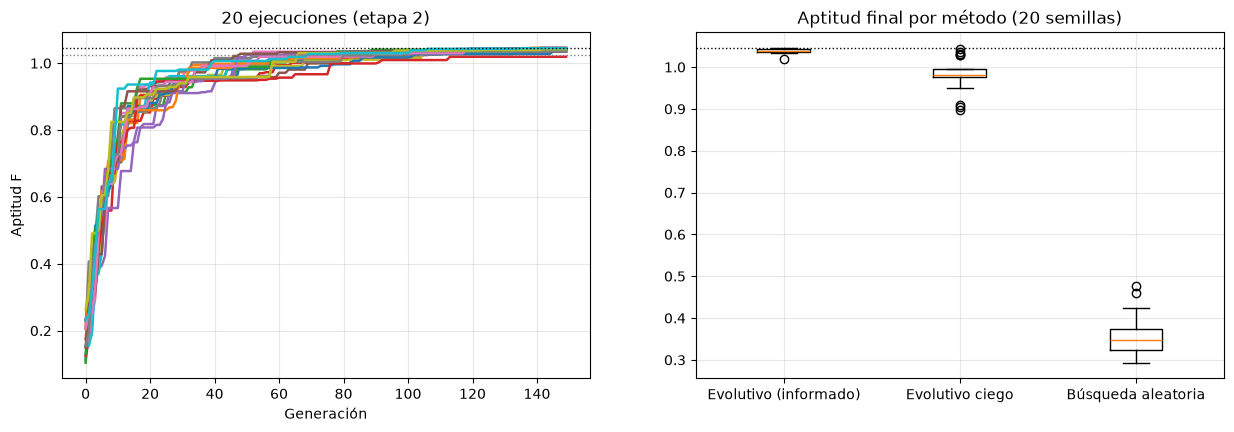

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
vz.grafica_evolucion([(f"semilla {f['semilla']}", f["historial"]) for f in p7["filas"]], cota=ev2.cota_superior(), ax=ejes[0],
                     titulo="20 ejecuciones (etapa 2)")
ejes[0].get_legend().remove()
datos = [[f["aptitud"] for f in p7["filas"]], [c["aptitud"] for c in p7["ciega"]], [a["aptitud"] for a in p7["aleatoria"]]]
ejes[1].boxplot(datos, tick_labels=list(p7["estadisticas"].keys()))
ejes[1].axhline(ev2.cota_superior(), color="black", ls=":", lw=1)
ejes[1].set_title("Aptitud final por método (20 semillas)"); ejes[1].grid(alpha=0.3)
plt.show()

**Interpretación.** Con 20 semillas distintas el algoritmo siempre devuelve una configuración válida; en 18 de 20 cubre las 6 regiones y cumple el criterio de "suficientemente buena". La aptitud varía poco (desviación ≈ 0.006), pero **las constelaciones no son iguales**: lo que más cambia es a qué regiones mandan los dos satélites sobrantes (a veces a las altas, a veces a una media). Solo 2 de 20 llegan exactamente a la cota. Las 2 corridas que fallan (semillas 113 y 116) dejan Desierto Kami parcial, el mismo patrón de la prueba 6a.

La comparación con referencias muestra que el resultado no es suerte. Con el mismo número de evaluaciones, la **búsqueda aleatoria** no pasa de F = 0.48, y la versión **ciega** del algoritmo (sin reubicación informada) solo cumple 4 de 20. Esa diferencia justifica usar conocimiento del problema en la mutación.

## 8. Prueba 8 (propia) — ¿Qué pasa si falla un satélite?

In [14]:
p8 = ex.prueba_resiliencia(ev2, r2.mejor)
print("Aptitud con los 8 satélites:", p8["aptitud_completa"])
tabla([f | {"regiones_perdidas": ", ".join(f["regiones_perdidas"]) or "ninguna"} for f in p8["filas"]],
      ["satelite_que_falla", "estaba_sobre", "aptitud", "caida", "regiones_cubiertas", "regiones_perdidas"],
      ["Satélite que falla", "Estaba sobre", "F con 7", "Caída", "Cubiertas", "Regiones que se pierden"])

Aptitud con los 8 satélites: 1.0462


| Satélite que falla | Estaba sobre | F con 7 | Caída | Cubiertas | Regiones que se pierden |
|---|---|---|---|---|---|
| 0 | Selva Namek | 1.0231 | 0.0231 | 6 | ninguna |
| 1 | Desierto Kami | 0.9692 | 0.0769 | 5 | Desierto Kami |
| 2 | Archipiélago Zenkai | 0.8923 | 0.1538 | 5 | Archipiélago Zenkai |
| 3 | Meseta Saiyan | 1.0231 | 0.0231 | 6 | ninguna |
| 4 | Valle Capsule | 0.8923 | 0.1538 | 5 | Valle Capsule |
| 5 | Selva Namek | 1.0231 | 0.0231 | 6 | ninguna |
| 6 | Meseta Saiyan | 1.0231 | 0.0231 | 6 | ninguna |
| 7 | Llanura Kaio | 0.8923 | 0.1538 | 5 | Llanura Kaio |

**Por qué esta prueba.** Busca una limitación del sistema: la aptitud premia la redundancia, pero ¿sirve de verdad? Si falla uno de los 4 satélites que están en regiones duplicadas (Meseta Saiyan y Selva Namek), **no se pierde ninguna región** (F baja solo 0.023). Si falla cualquiera de los otros 4, su región queda sin cobertura. La redundancia protege justo a las regiones de prioridad alta, que es lo que buscaba el criterio. El límite: con 8 satélites y 6 regiones, 4 regiones siempre dependen de un solo satélite.

## 9. Prueba 9 (propia) — ¿Los 37 puntos de muestra engañan?

In [15]:
soluciones = [(f"semilla {f['semilla']}", f["mejor"]) for f in p7["filas"]] + [("semilla 42", r2.mejor)]
p9 = ex.prueba_muestreo(soluciones)
print(f"Se revisaron {p9['soluciones_revisadas']} soluciones finales con {p9['puntos_densos']} puntos por región en vez de 37.")
print("Regiones donde la cobertura medida cambia:")
tabla(p9["diferencias"]) if p9["diferencias"] else print("ninguna")
print("Cambios de estado (cubierta ↔ no cubierta):", p9["cambios_de_estado"])

Se revisaron 21 soluciones finales con 121 puntos por región en vez de 37.
Regiones donde la cobertura medida cambia:


| solucion | region | cobertura_37 | cobertura_121 | cubierta_37 | cubierta_121 |
|---|---|---|---|---|---|
| semilla 113 | Desierto Kami | 0.811 | 0.81 | no | no |
| semilla 116 | Desierto Kami | 0.946 | 0.967 | no | sí |
| semilla 118 | Meseta Saiyan | 1 | 0.983 | sí | sí |

Cambios de estado (cubierta ↔ no cubierta): 1


**Por qué esta prueba.** Busca un posible **error de nuestra propia implementación**: la cobertura se estima con 37 puntos y el algoritmo optimiza justo esa estimación, así que podría "aprovecharse" de los huecos entre puntos. Al revisar con 121 puntos aparecieron diferencias en 3 de 126 casos (21 soluciones × 6 regiones). En uno, una región que con 37 puntos se veía al 100 % tiene en realidad un hueco (98.3 %). En otro, una región pasa de "no cubierta" a "cubierta". El error es pequeño y no cambia ninguna conclusión, pero confirma que **el 100 % de cobertura es una estimación**. Mejora posible: evaluar con más puntos al final o usar la cobertura densa para el reporte.

## 10. Prueba 10 — Cambio en las condiciones (sección 3.3)

In [16]:
p10 = ex.prueba_cambio_condiciones(ev2, r2.mejor)
for caso in p10:
    a, n = caso["anterior"], caso["nueva"]
    display(Markdown(f"**{caso['caso']}** — nueva cota: {caso['cota_nueva']}"))
    print(f"  Configuración anterior → válida: {a['valida']}, F = {a['aptitud']} ({a['porcentaje_cota']} % de la nueva cota), duplica: {caso['anterior_dobles']}")
    print(f"  Nueva corrida           → válida: {n['valida']}, F = {n['aptitud']} ({n['porcentaje_cota']} %), cubiertas {n['regiones_cubiertas']}/6, duplica: {caso['nueva_dobles']}")

**a) Selva Namek baja de alta a normal** — nueva cota: 1.0455

  Configuración anterior → válida: True, F = 1.0364 (99.1 % de la nueva cota), duplica: ['Meseta Saiyan', 'Selva Namek']
  Nueva corrida           → válida: True, F = 1.0435 (99.8 %), cubiertas 6/6, duplica: ['Meseta Saiyan']


**b) Se cierra la zona donde estaba un satélite (2° alrededor del que ve Llanura Kaio)** — nueva cota: 1.0462

  Configuración anterior → válida: False, F = 1.0462 (100.0 % de la nueva cota), duplica: ['Meseta Saiyan', 'Selva Namek']
  Nueva corrida           → válida: True, F = 1.0385 (99.3 %), cubiertas 6/6, duplica: ['Meseta Saiyan', 'Valle Capsule']


In [17]:
vz.globo_3d(p10[1]["evaluador"], p10[1]["resultado"].mejor, titulo=p10[1]["caso"], inicial=r2.mejor).show()

**Interpretación.**

- **a) Cambia una prioridad.** La configuración anterior **sigue siendo válida** (las prioridades no afectan las restricciones), pero ya no es la mejor: gasta redundancia en Selva Namek, que ahora es normal. Al volver a correr, el algoritmo deja de duplicar Selva Namek. Validez y calidad son cosas distintas: un cambio de prioridad nunca invalida una constelación, solo la hace menos conveniente.
- **b) Se cierra una zona.** Se pone una zona nueva de 2° justo donde estaba el satélite que ve Llanura Kaio. La configuración anterior se vuelve **inválida**, aunque su aptitud siga siendo la máxima, y el sistema lo detecta. La nueva corrida encuentra una alternativa válida que cubre las 6 regiones. En el globo, el botón "Configuración inicial" muestra la constelación anterior con el satélite en rojo dentro de la zona nueva.

## 11. Visor 3D principal

El visor `resultados/astroshield_3d.html` junta las corridas de arriba en una sola página hecha con Three.js:

- planeta Veguitto con relieve, océanos, nubes, atmósfera y bioluminiscencia en el lado nocturno;
- nubes de escombros y objetos ocupados a la altura de la órbita;
- satélites con su cono de visión y su huella;
- **línea de tiempo** que reproduce las 150 generaciones reales (la mejor configuración de cada una);
- un **guía** que vuela a la región elegida, la señala y explica sus datos de esa generación.

Se abre con doble clic en el navegador (necesita internet para cargar Three.js). Se pueden agregar modelos 3D propios (.stl, .obj) como guías; se quedan en el navegador de quien los carga y no forman parte del repositorio.

In [18]:
casos_visor = [
    ("etapa2", "Etapa 2 — escenario del enunciado", "Las 3 zonas de escombros y los 2 objetos ocupados del enunciado. Semilla 42.", ev2, r2),
    ("etapa1", "Etapa 1 — sin restricciones", "Solo las 6 regiones, sin zonas prohibidas. Semilla 42.", p1["etapa1"]["evaluador"], p1["etapa1"]["resultado"]),
    ("p5", "P5 — nube de escombros sobre Meseta Saiyan", "Zona nueva de 2.5° justo encima de Meseta Saiyan: el algoritmo la rodea con dos satélites.",
     p5["caso_saiyan"]["evaluador"], p5["caso_saiyan"]["resultado"]),
    ("p6a", "P6a — Objeto B sobre Desierto Kami", "Condición difícil: el centro de Desierto Kami ya no se puede ver desde ninguna posición permitida.", p6[0]["evaluador"], p6[0]["resultado"]),
    ("p6b", "P6b — Meseta Saiyan bloqueada", "Inviable para una región: una zona de 9° impide observar Meseta Saiyan.", p6[1]["evaluador"], p6[1]["resultado"]),
    ("p6c", "P6c — todo el planeta prohibido", "Inviable total: no existe ninguna configuración válida; el sistema devuelve la que menos viola y la marca inválida.", p6[2]["evaluador"], p6[2]["resultado"]),
    ("p10b", "P10b — se cierra una zona", "Zona nueva de 2° donde estaba el satélite que veía Llanura Kaio; el algoritmo busca otra configuración.", p10[1]["evaluador"], p10[1]["resultado"]),
]
ruta = vz.exportar_visor([vz.datos_visor(*c) for c in casos_visor], "resultados/astroshield_3d.html")
print("Visor escrito en", ruta)
from IPython.display import IFrame, HTML
# En Colab el visor se incrusta directo; en Jupyter local se abre el archivo.
HTML(Path(ruta).read_text(encoding="utf-8")) if EN_COLAB else IFrame(ruta, width="100%", height=760)

Visor escrito en resultados/astroshield_3d.html


## 12. Conclusión

- El algoritmo evolutivo **genera, evalúa y mejora** configuraciones: pasa de 0/6 a 6/6 regiones y, en 18 de 20 corridas, llega a menos del 2 % de una cota superior calculada aparte.
- Las restricciones **se cumplen siempre** que existe una solución válida, y cuando no existe el sistema lo dice en vez de esconderlo.
- Las diferencias entre corridas están en **dónde se pone la redundancia**, no en la cobertura principal.
- Limitaciones encontradas con las pruebas: el criterio permite abandonar una región de prioridad normal cuando es difícil (6a), la cota superior deja de ser alcanzable cuando hay zonas sobre las regiones (5) y la cobertura con 37 puntos es una estimación (9).

El análisis completo está en `docs/04-analisis-de-resultados.md`.